# 07.3 · Smoothing and Holt-Winters

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/03-smoothing-holt-winters/lesson.ipynb)

Read the [README](README.md) and do the five-step table first. This notebook reproduces it, then fits simple exponential smoothing, Holt and Holt-Winters to ShopWave's weekly revenue and puts each through the 07.2 backtest.

## 1. Simple exponential smoothing by hand

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

y = [100, 120, 110, 130, 125]      # £k, five weeks

def ses_by_hand(y, alpha):
    level = y[0]                    # start the level at the first value
    rows = []
    for t in range(1, len(y)):
        forecast = level            # forecast for week t is the level so far
        level = alpha * y[t] + (1 - alpha) * level
        rows.append({"week": t + 1, "actual": y[t], "forecast": forecast,
                     "error": y[t] - forecast, "new level": level})
    return pd.DataFrame(rows)

ses_by_hand(y, alpha=0.5)

,week,actual,forecast,error,new level
0,2,120,100.0,20.0,110.0
1,3,110,110.0,0.0,110.0
2,4,130,110.0,20.0,120.0
3,5,125,120.0,5.0,122.5


In [2]:
ses_by_hand(y, alpha=0.2).round(2)

,week,actual,forecast,error,new level
0,2,120,100.00,20.00,104.00
1,3,110,104.00,6.00,105.20
2,4,130,105.20,24.80,110.16
3,5,125,110.16,14.84,113.13


With α = 0.5 the level chases every new week: after week 5 it is 122.5. With α = 0.2 it moves cautiously and ends at 113.13. Neither is "right"; α is chosen by fitting, which is what statsmodels does next. First, check statsmodels gives exactly your numbers when α is fixed:

In [3]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

fit = SimpleExpSmoothing(np.array(y, dtype=float), initialization_method="known",
                         initial_level=y[0]).fit(smoothing_level=0.5, optimized=False)
print("fitted values (one-step forecasts):", fit.fittedvalues.round(2))
print("forecast for week 6:", fit.forecast(1).round(2))

fitted values (one-step forecasts): [100. 100. 110. 110. 120.]
forecast for week 6: [122.5]


The first fitted value is 100: statsmodels "forecasts" week 1 with the starting level. After that, every number matches the table.

## 2. ShopWave's weekly revenue

In [4]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

H = 5                                                   # forecast 5 weeks ahead
ORIGINS = pd.date_range("2011-04-03", periods=8, freq="4W-SUN")      # 3 Apr ... 16 Oct 2011

def backtest(forecast_fn, series=None, origins=ORIGINS, h=H):
    """Rolling-origin backtest: at each origin, fit on the past, forecast h weeks, score MAE."""
    series = weekly if series is None else series
    rows = []
    for origin in origins:
        train = series[series.index <= origin]
        test = series[series.index > origin].iloc[:h]
        pred = np.asarray(forecast_fn(train, len(test)))
        rows.append({"origin": origin.date(), "MAE": np.abs(test.values - pred).mean()})
    return pd.DataFrame(rows)

def naive(train, h):          return np.repeat(train.iloc[-1], h)
def mean_fc(train, h):        return np.repeat(train.mean(), h)
def seasonal_naive(train, h): return train.iloc[-52:-52 + h].values
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

def ses(train, h):
    return SimpleExpSmoothing(train, initialization_method="estimated").fit().forecast(h).values

def holt(train, h):
    return ExponentialSmoothing(train, trend="add", damped_trend=True,
                                initialization_method="estimated").fit().forecast(h).values

from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, h):
    """Additive Holt-Winters, seeded with the first year as the starting seasonal pattern."""
    first = train.iloc[:52]
    model = ExponentialSmoothing(
        train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52,
        initialization_method="known", initial_level=first.mean(), initial_trend=0.0,
        initial_seasonal=(first - first.mean()).values).fit()
    return model.forecast(h).values

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


## 3. Simple exponential smoothing and Holt, fitted

SES has one knob (α, how fast the level reacts). Holt adds a trend with its own knob (β), plus a **damping** factor φ that flattens the trend the further ahead you go. Without damping, a trend fitted on the autumn climb would forecast revenue rising forever.

In [5]:
train = weekly[weekly.index <= "2011-10-16"]
f_ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
f_holt = ExponentialSmoothing(train, trend="add", damped_trend=True,
                              initialization_method="estimated").fit()
print(f"SES:  alpha = {f_ses.params['smoothing_level']:.3f}")
print(f"Holt: alpha = {f_holt.params['smoothing_level']:.3f}, beta = {f_holt.params['smoothing_trend']:.3f}, "
      f"phi = {f_holt.params['damping_trend']:.3f}")

SES:  alpha = 0.586
Holt: alpha = 0.534, beta = 0.000, phi = 0.800


SES picks α ≈ 0.59: the level moves more than halfway towards each new week. Holt's trend knob β comes out at **0**: it finds no lasting trend in ShopWave's weekly revenue, which agrees with the flat trend line you saw in 07.1. So on this series Holt behaves almost exactly like SES.

## 4. Holt-Winters: adding the season

Holt-Winters adds a seasonal component with its own knob (γ), one value per week of the year. statsmodels' default way of choosing the 52 starting seasonal values needs **two full years** of data before the forecast origin. ShopWave's series starts in December 2009, so at every backtest origin there are fewer than 104 weeks:

In [6]:
try:
    ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=52,
                         initialization_method="estimated").fit()
except ValueError as e:
    print("ValueError:", e)
print("weeks available at the last origin:", len(train))

ValueError: Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.
weeks available at the last origin: 98


The fix is to tell the model where to start: use the **first year** of data as the initial seasonal pattern (each week's distance from the first-year average), the first-year average as the initial level, and zero as the initial trend. That is `initialization_method="known"`, wrapped in `holt_winters()` above. The model then learns α, β and γ from everything that follows.

In [7]:
first = train.iloc[:52]
f_hw = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52,
                            initialization_method="known", initial_level=first.mean(), initial_trend=0.0,
                            initial_seasonal=(first - first.mean()).values).fit()
print({k: round(float(f_hw.params[k]), 3) for k in
       ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]})

{'smoothing_level': 0.0, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0, 'damping_trend': 0.8}


Look at the fitted knobs: α, β and γ come out at (or very close to) **zero**. The model has decided the best thing it can do is *keep the first-year pattern and the first-year level unchanged*. In other words, with only one year after the seed, Holt-Winters has almost nothing to learn and collapses into something very close to seasonal naive. That is not a bug; it is the data telling you two years is too short for this model to add much.

## 5. The backtest

In [8]:
models = [("seasonal naive", seasonal_naive), ("SES", ses), ("Holt (damped)", holt),
          ("Holt-Winters", holt_winters)]
per_origin = pd.DataFrame({name: backtest(fn)["MAE"] for name, fn in models}).set_axis(
    [o.date() for o in ORIGINS])
(per_origin / 1000).round(1)

,seasonal naive,SES,Holt (damped),Holt-Winters
2011-04-03,29.9,24.6,23.4,21.7
2011-05-01,22.9,63.5,65.9,46.1
2011-05-29,25.2,38.6,38.8,27.0
2011-06-26,27.0,19.8,20.5,26.4
2011-07-24,16.1,9.1,9.7,20.1
2011-08-21,41.3,52.3,52.6,41.7
2011-09-18,75.2,62.4,66.1,72.3
2011-10-16,21.9,29.2,27.9,21.9


In [9]:
(per_origin.mean().sort_values() / 1000).round(1).rename("mean MAE £k")

seasonal naive    32.4
Holt-Winters      34.7
SES               37.4
Holt (damped)     38.1
Name: mean MAE £k, dtype: float64

On average, SES and Holt, which know nothing about seasons, do worse than seasonal naive. They react to the last few weeks and miss every turn of the year (look at 1 May, the bank-holiday week). They do win the quiet summer origins (26 June, 24 July), when "like the last few weeks" is the right idea. Holt-Winters is close to seasonal naive on average but does not beat it. The ranking is the honest result for a two-year history.

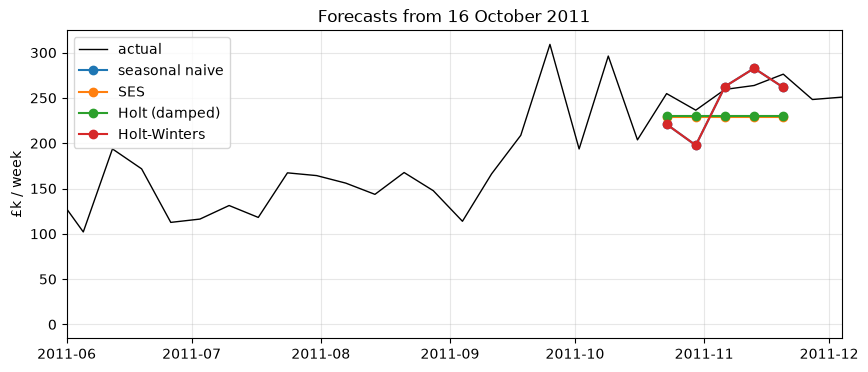

In [10]:
test_idx = weekly.index[weekly.index > "2011-10-16"][:H]
plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly / 1000, color="black", linewidth=1, label="actual")
for name, fn in models:
    plt.plot(test_idx, fn(train, H) / 1000, marker="o", label=name)
plt.xlim(pd.Timestamp("2011-06-01"), weekly.index[-1]); plt.ylabel("£k / week")
plt.legend(); plt.grid(alpha=.3); plt.title("Forecasts from 16 October 2011"); plt.show()

From the last origin the smoothers without a season flatten out at the recent level, while the seasonal models follow last year's November climb.

## Quiz answers

1. α controls how fast the level reacts. α near 1: the forecast is almost the last value (naive). α near 0: the forecast barely moves (close to the long-run mean).
2. ℓ = 0.3 × 140 + 0.7 × 120 = 42 + 84 = **126**.
3. Damping shrinks the trend the further ahead you forecast, so a temporary climb is not extrapolated forever.
4. Its default initialisation needs two full seasons (104 weeks) before the origin, and ShopWave has fewer at every backtest origin.
5. α, β and γ near zero mean the model keeps its starting level, trend and seasonal pattern almost unchanged: it effectively repeats the first year, which makes it very similar to seasonal naive.

**Next:** [07.4 ARIMA and SARIMA](../04-arima-sarima/)